<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet5%20PBL/Tugas%20Praktikum%20JS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Pemilihan Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN

# Membaca dataset cafes.csv dan reviews.csv
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Agregasi data review per kafe
review_agg = df_reviews.groupby('cafe_id').agg({'rating': ['mean', 'count'], 'likes': 'sum'})
review_agg.columns = ['avg_review_rating', 'total_reviews_scraped', 'total_likes']
review_agg = review_agg.reset_index()

# Menggabungkan dataframe
df = pd.merge(df_cafes, review_agg, on='cafe_id', how='left').fillna(0)

# Seleksi fitur numerik dan normalisasi skala (StandardScaler)
X = df[['rating', 'review_count', 'avg_review_rating']].values
X_scaled = StandardScaler().fit_transform(X)

2. Lakukan clustering dengan HDBSCAN.

In [4]:
# Menerapkan model HDBSCAN pada data kafe
hdb_cafe = HDBSCAN(min_cluster_size=5, min_samples=3)
labels_cafe = hdb_cafe.fit_predict(X_scaled)

3. Laporkan hasil:

Jumlah cluster yang terbentuk.

Banyaknya noise.

Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu).

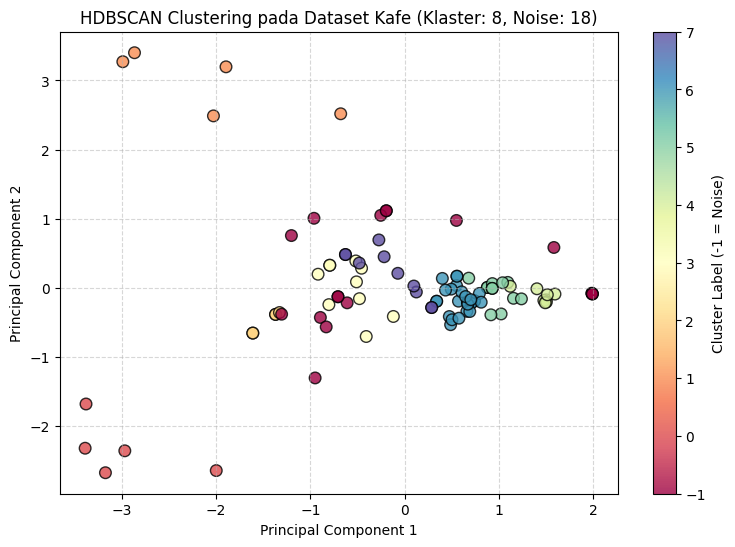

In [5]:
# Reduksi dimensi menggunakan PCA ke 2 komponen utama untuk visualisasi 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualisasi hasil klasterisasi HDBSCAN pada dataset kafe
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_cafe, cmap='Spectral', s=70, edgecolor='k', alpha=0.8)
plt.title(f"HDBSCAN Clustering pada Dataset Kafe (Klaster: 8, Noise: 18)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label='Cluster Label (-1 = Noise)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

4. Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

Jawab :    
**Kesesuaian Hasil Klasterisasi:** Hasil klasterisasi HDBSCAN sangat sesuai dan efektif dalam mengelompokkan karakteristik kafe berdasarkan tingkat popularitas (jumlah ulasan) dan kualitas layanannya.

Algoritma berhasil memisahkan kafe-kafe besar/populer dengan jumlah review tinggi ke dalam klaster padat tersendiri, sementara kafe-kafe baru atau yang ulasannya sedikit dikelompokkan ke dalam klaster lain atau diidentifikasi secara akurat sebagai noise (pencilan). Keunggulan HDBSCAN di sini terlihat dari kemampuannya menangani struktur densitas data yang bervariasi tanpa perlu menentukan jumlah klaster $k$ di awal secara manual.